In [1]:
import os
import platform
import time
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import polars as pl
import numpy as np
import statistics
import shutil
import sys
import psutil


# Configuración de rutas
REPO = os.path.expanduser("~/big-data-postgraduate")
INPUT = (
    "/home/tuptc/big-data-postgraduate/kit/data/processed/eva_preparada.parquet"
)
OUT = os.path.join(REPO, "kit/salidas/soluciones/PD05")

os.makedirs(OUT, exist_ok=True)

# Carga inicial en ambos motores
datos_pd = pd.read_parquet(INPUT, engine="pyarrow")
datos_pl = pl.read_parquet(INPUT)

print("Entrada:", INPUT)
print("Salidas:", OUT)
print(platform.platform())
print(
    "pandas:",
    pd.__version__,
    "| Polars:",
    pl.__version__,
    "| GeoPandas:",
    gpd.__version__,
)

Entrada: /home/tuptc/big-data-postgraduate/kit/data/processed/eva_preparada.parquet
Salidas: /home/tuptc/big-data-postgraduate/kit/salidas/soluciones/PD05
Linux-6.18.40.1-microsoft-standard-WSL2-x86_64-with-glibc2.43
pandas: 2.2.3 | Polars: 1.35.2 | GeoPandas: 1.2.0


In [2]:
# 1. Contrato común y consulta

# Proyección común y normalización de tipos
# Columnas requeridas
cols_requeridas = ["codigo_departamento","codigo_municipio","anio","cultivo","area_ha","produccion_t",]

# Proyección en Pandas
proyeccion_pd = datos_pd[cols_requeridas].copy()
proyeccion_pd["codigo_departamento"] = (proyeccion_pd["codigo_departamento"].astype(str).str.split(".").str[0].str.zfill(2))
proyeccion_pd["codigo_municipio"] = (proyeccion_pd["codigo_municipio"].astype(str).str.split(".").str[0].str.zfill(5))
proyeccion_pd["area_ha"] = proyeccion_pd["area_ha"].astype(float)
proyeccion_pd["produccion_t"] = proyeccion_pd["produccion_t"].astype(float)

# Proyección equivalente en Polars
proyeccion_pl = datos_pl.select([
    pl.col("codigo_departamento").cast(pl.Utf8).str.split(".").list.get(0).str.zfill(2),
    pl.col("codigo_municipio").cast(pl.Utf8).str.split(".").list.get(0).str.zfill(5),
    pl.col("anio"),
    pl.col("cultivo"),
    pl.col("area_ha").cast(pl.Float64),pl.col("produccion_t").cast(pl.Float64),])

# Elección de Parámetros de Prueba (En este caso el año y departamento con mayor frecuencia)
ANIO_FILTRO = proyeccion_pd["anio"].dropna().value_counts().index[0]
DEPTO_FILTRO = (proyeccion_pd["codigo_departamento"].dropna().value_counts().index[0])
print(f"Filtro aplicado -> Año: {ANIO_FILTRO} | Departamento: {DEPTO_FILTRO}\n")

#  Consulta en Pandas
df_filtrado_pd = proyeccion_pd[(proyeccion_pd["anio"] == ANIO_FILTRO)
    & (proyeccion_pd["codigo_departamento"] == DEPTO_FILTRO)].copy()

res_pd = (df_filtrado_pd.groupby("codigo_municipio", dropna=False)
    .agg(total_registros=("cultivo", "count"),area_total_ha=("area_ha", "sum"),produccion_promedio_t=("produccion_t", "mean"),)
    .reset_index()
    .sort_values("codigo_municipio", na_position="last")
    .reset_index(drop=True))

# Consulta en Polars
res_pl = (proyeccion_pl.filter((pl.col("anio") == ANIO_FILTRO)
        & (pl.col("codigo_departamento") == DEPTO_FILTRO)    )
    .group_by("codigo_municipio").agg([pl.len().alias("total_registros"),pl.col("area_ha").sum().alias("area_total_ha"),pl.col("produccion_t").mean().alias("produccion_promedio_t"),])
    .sort("codigo_municipio", descending=False, nulls_last=True))

# Comparación de Resultados entre consultas
res_pl_pd = res_pl.to_pandas()

coinciden_claves = (res_pd["codigo_municipio"].equals(res_pl_pd["codigo_municipio"])
    or (res_pd["codigo_municipio"].fillna("") == res_pl_pd["codigo_municipio"].fillna("")).all())
coinciden_conteos = (res_pd["total_registros"] == res_pl_pd["total_registros"]).all()

diferencia_area = ((res_pd["area_total_ha"] - res_pl_pd["area_total_ha"]).abs().max())
diferencia_prod = ((res_pd["produccion_promedio_t"] - res_pl_pd["produccion_promedio_t"]).abs().max())

print("Indicadores de control")
print(f"1. ¿Coinciden las claves municipales?: {coinciden_claves}")
print(f"2. ¿Coinciden los conteos de registros?: {coinciden_conteos}")
print(f"3. Máxima diferencia absoluta en área total: {diferencia_area:.8f}")
print("4. Máxima diferencia absoluta en promedio de producción:"f" {diferencia_prod:.8f}")
print("5. ¿Cumple tolerancia (abs <= 0.000001)?: "f"{(diferencia_prod <= 0.000001 or pd.isna(diferencia_prod)) and (diferencia_area <= 0.000001 or pd.isna(diferencia_area))}\n")

display(res_pd.head())

Filtro aplicado -> Año: 2025 | Departamento: 15

Indicadores de control
1. ¿Coinciden las claves municipales?: True
2. ¿Coinciden los conteos de registros?: True
3. Máxima diferencia absoluta en área total: 0.00000000
4. Máxima diferencia absoluta en promedio de producción: 0.00000000
5. ¿Cumple tolerancia (abs <= 0.000001)?: True



,codigo_municipio,total_registros,area_total_ha,produccion_promedio_t
0,15001,28,5874.50,4162.436786
1,15022,19,226.33,231.822105
2,15047,17,3939.91,8580.726471
3,15051,16,2404.26,3506.945625
4,15087,29,1089.00,561.427931


In [3]:
# 2. Particionamiento manual desde pandas

# Definición de la carpeta de ejecución
EJECUCION = Path(OUT) / "ejecucion_01"
if EJECUCION.exists():
  shutil.rmtree(EJECUCION)
EJECUCION.mkdir(parents=True, exist_ok=True)

print(f"Directorio para el particionamiento: {EJECUCION}\n")

# Asegurar id_fila para controles de unicidad
if "id_fila" not in proyeccion_pd.columns:
  proyeccion_pd = proyeccion_pd.reset_index(drop=True)
  proyeccion_pd["id_fila"] = proyeccion_pd.index

# Archivo único: CSV y Parquet
ruta_csv_unico = EJECUCION / "datos_unicos.csv"
ruta_parquet_unico = EJECUCION / "datos_unicos.parquet"

proyeccion_pd.to_csv(ruta_csv_unico, index=False)
proyeccion_pd.to_parquet(ruta_parquet_unico, engine="pyarrow", compression="snappy", index=False)

print(f"Archivo CSV único escrito ({ruta_csv_unico.stat().st_size:,} bytes)")
print("Archivo Parquet único escrito"f" ({ruta_parquet_unico.stat().st_size:,} bytes)\n")

# Organización 1: Particionado por año
carpeta_anio = EJECUCION / "por_anio"
carpeta_anio.mkdir(parents=True, exist_ok=True)

inventario_anio = []
for numero, (anio, grupo) in enumerate(proyeccion_pd.groupby("anio", dropna=False, sort=True)):
  archivo = carpeta_anio / f"parte-{numero:04d}.parquet"
  grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
  inventario_anio.append({"anio": anio,"archivo": str(archivo.relative_to(EJECUCION)),"filas": len(grupo),"bytes": archivo.stat().st_size,})

df_inventario_anio = pd.DataFrame(inventario_anio)
ruta_inv_anio = EJECUCION / "inventario_anio.csv"
df_inventario_anio.to_csv(ruta_inv_anio, index=False)
print(f"Particionado 'por_anio' completado: {len(df_inventario_anio)} partes.")

# Organización 2: Particionado por año y departamento
carpeta_anio_depto = EJECUCION / "por_anio_depto"
carpeta_anio_depto.mkdir(parents=True, exist_ok=True)

inventario_anio_depto = []
for numero, ((anio, depto), grupo) in enumerate(
    proyeccion_pd.groupby(
        ["anio", "codigo_departamento"], dropna=False, sort=True)):
  archivo = carpeta_anio_depto / f"parte-{numero:04d}.parquet"
  grupo.to_parquet(archivo, engine="pyarrow", compression="snappy", index=False)
  inventario_anio_depto.append({"anio": anio,"codigo_departamento": depto,"archivo": str(archivo.relative_to(EJECUCION)),"filas": len(grupo),"bytes": archivo.stat().st_size,})

df_inventario_anio_depto = pd.DataFrame(inventario_anio_depto)
ruta_inv_anio_depto = EJECUCION / "inventario_anio_depto.csv"
df_inventario_anio_depto.to_csv(ruta_inv_anio_depto, index=False)
print("Particionado 'por_anio_depto' :"f" {len(df_inventario_anio_depto)} partes.\n")

# Relectura y Control
# Relectura del inventario asignando tipos explícitos para preservar ceros iniciales
inv_releido = pd.read_csv(ruta_inv_anio_depto, dtype={"anio": "Int64", "codigo_departamento": str})

# Reconstrucción de la tabla completa
partes_releidas = []
for rel_path in inv_releido["archivo"]:
  abs_path = EJECUCION / rel_path
  partes_releidas.append(pd.read_parquet(abs_path, engine="pyarrow"))

df_reconstruido = pd.concat(partes_releidas, ignore_index=True)

# Métricas de verificación según la guía
filas_originales = len(proyeccion_pd)
filas_reconstruidas = len(df_reconstruido)
conserva_filas = filas_originales == filas_reconstruidas

# Ordenamiento de control estricto por id_fila
orig_sorted = proyeccion_pd.sort_values("id_fila").reset_index(drop=True)
recon_sorted = df_reconstruido.sort_values("id_fila").reset_index(drop=True)

registros_identicos = orig_sorted.equals(recon_sorted)
unicidad_ids = (recon_sorted["id_fila"].nunique() == len(recon_sorted)) and recon_sorted["id_fila"].equals(orig_sorted["id_fila"])

print("Resumen")
print("Filas totales (Original vs Reconstruido):"f" {filas_originales} == {filas_reconstruidas} -> {conserva_filas}")
print(f"1. Unicidad y conservación de IDs (id_fila): {unicidad_ids}")
print(f"2. Conservación perfecta del contenido: {registros_identicos}")
print(f"3. Bytes Parquet Único: {ruta_parquet_unico.stat().st_size:,} B")
print(f"4. Bytes 'por_anio': {df_inventario_anio['bytes'].sum():,} B")
print(f"5. Bytes 'por_anio_depto': {df_inventario_anio_depto['bytes'].sum():,} B")
display(df_inventario_anio_depto.head())

Directorio para el particionamiento: /home/tuptc/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_01

Archivo CSV único escrito (6,496,466 bytes)
Archivo Parquet único escrito (1,786,182 bytes)

Particionado 'por_anio' completado: 7 partes.
Particionado 'por_anio_depto' : 224 partes.

Resumen
Filas totales (Original vs Reconstruido): 166732 == 166732 -> True
1. Unicidad y conservación de IDs (id_fila): True
2. Conservación perfecta del contenido: True
3. Bytes Parquet Único: 1,786,182 B
4. Bytes 'por_anio': 2,046,800 B
5. Bytes 'por_anio_depto': 3,313,040 B


,anio,codigo_departamento,archivo,filas,bytes
0,2019,05,por_anio_depto/parte-0000.parquet,1916,29710
1,2019,08,por_anio_depto/parte-0001.parquet,357,9488
2,2019,13,por_anio_depto/parte-0002.parquet,565,12683
3,2019,15,por_anio_depto/parte-0003.parquet,2261,31144
4,2019,17,por_anio_depto/parte-0004.parquet,433,10852


In [4]:
# 3. Lectura y escritura comparables

# Documentación del Entorno (Hardware / Software)
print("Entorno de ejecución")
print(f"Sistema Operativo: {platform.system()} {platform.release()}")
print("CPU:"f" {platform.processor() if platform.processor() else 'Procesador estándar'}")
print(f"RAM Disponible: {psutil.virtual_memory().total / (1024**3):.2f} GB")
print(f"Versión de Python: {sys.version.split()[0]}")
print(f"Versión de Pandas: {pd.__version__}")
print(f"Versión de Polars: {pl.__version__}\n")

# Rutas de prueba para escritura
DIR_BENCHMARK = Path(OUT) / "benchmark_io"
DIR_BENCHMARK.mkdir(parents=True, exist_ok=True)


# Funciones de Medición (Lectura y Escritura)


# Uso de Pandas
def medir_lectura_pd_csv(path):
  t0 = time.perf_counter()
  df = pd.read_csv(path, dtype={"codigo_departamento": str, "codigo_municipio": str})
  df["codigo_departamento"] = df["codigo_departamento"].str.zfill(2)
  df["codigo_municipio"] = df["codigo_municipio"].str.zfill(5)
  df["area_ha"] = df["area_ha"].astype(float)
  df["produccion_t"] = df["produccion_t"].astype(float)
  tf = time.perf_counter()
  return (tf - t0) * 1000, df

def medir_lectura_pd_pq(path):
  t0 = time.perf_counter()
  df = pd.read_parquet(path, engine="pyarrow")
  df["codigo_departamento"] = (df["codigo_departamento"].astype(str).str.zfill(2))
  df["codigo_municipio"] = df["codigo_municipio"].astype(str).str.zfill(5)
  df["area_ha"] = df["area_ha"].astype(float)
  df["produccion_t"] = df["produccion_t"].astype(float)
  tf = time.perf_counter()
  return (tf - t0) * 1000, df


def medir_escritura_pd_csv(df, path):
  t0 = time.perf_counter()
  df.to_csv(path, index=False)
  tf = time.perf_counter()
  return (tf - t0) * 1000

def medir_escritura_pd_pq(df, path):
  t0 = time.perf_counter()
  df.to_parquet(path, engine="pyarrow", compression="snappy", index=False)
  tf = time.perf_counter()
  return (tf - t0) * 1000

# Uso de Polars
def medir_lectura_pl_csv(path):
  t0 = time.perf_counter()
  df = pl.read_csv(path,schema_overrides={"codigo_departamento": pl.Utf8,"codigo_municipio": pl.Utf8,},
  ).select([
      pl.col("codigo_departamento").str.zfill(2),
      pl.col("codigo_municipio").str.zfill(5),
      pl.col("anio"),
      pl.col("cultivo"),
      pl.col("area_ha").cast(pl.Float64),
      pl.col("produccion_t").cast(pl.Float64),])
  tf = time.perf_counter()
  return (tf - t0) * 1000, df


def medir_lectura_pl_pq(path):
  t0 = time.perf_counter()
  df = pl.read_parquet(path).select([
      pl.col("codigo_departamento").cast(pl.Utf8).str.zfill(2),
      pl.col("codigo_municipio").cast(pl.Utf8).str.zfill(5),
      pl.col("anio"),
      pl.col("cultivo"),
      pl.col("area_ha").cast(pl.Float64),
      pl.col("produccion_t").cast(pl.Float64),])
  tf = time.perf_counter()
  return (tf - t0) * 1000, df


def medir_escritura_pl_csv(df, path):
  t0 = time.perf_counter()
  df.write_csv(path)
  tf = time.perf_counter()
  return (tf - t0) * 1000

def medir_escritura_pl_pq(df, path):
  t0 = time.perf_counter()
  df.write_parquet(path, compression="snappy")
  tf = time.perf_counter()
  return (tf - t0) * 1000

# Ejecución de Pruebas: Warmup (1) + Repeticiones (5)

N_REP = 5
resultados = []

# Warmup inicial (fuera de medición)
_ = medir_lectura_pd_csv(ruta_csv_unico)
_ = medir_lectura_pl_csv(ruta_csv_unico)

for i in range(1, N_REP + 1):
  out_csv_pd = DIR_BENCHMARK / f"pd_out_{i}.csv"
  out_pq_pd = DIR_BENCHMARK / f"pd_out_{i}.parquet"
  out_csv_pl = DIR_BENCHMARK / f"pl_out_{i}.csv"
  out_pq_pl = DIR_BENCHMARK / f"pl_out_{i}.parquet"

  # Alternación entre iteraciones para evitar sesgo de orden
  if i % 2 != 0:
    t_lec_pd_csv, _ = medir_lectura_pd_csv(ruta_csv_unico)
    t_esc_pd_csv = medir_escritura_pd_csv(proyeccion_pd, out_csv_pd)
    t_lec_pd_pq, _ = medir_lectura_pd_pq(ruta_parquet_unico)
    t_esc_pd_pq = medir_escritura_pd_pq(proyeccion_pd, out_pq_pd)

    t_lec_pl_csv, _ = medir_lectura_pl_csv(ruta_csv_unico)
    t_esc_pl_csv = medir_escritura_pl_csv(proyeccion_pl, out_csv_pl)
    t_lec_pl_pq, _ = medir_lectura_pl_pq(ruta_parquet_unico)
    t_esc_pl_pq = medir_escritura_pl_pq(proyeccion_pl, out_pq_pl)
  else:
    t_lec_pl_csv, _ = medir_lectura_pl_csv(ruta_csv_unico)
    t_esc_pl_csv = medir_escritura_pl_csv(proyeccion_pl, out_csv_pl)
    t_lec_pl_pq, _ = medir_lectura_pl_pq(ruta_parquet_unico)
    t_esc_pl_pq = medir_escritura_pl_pq(proyeccion_pl, out_pq_pl)

    t_lec_pd_csv, _ = medir_lectura_pd_csv(ruta_csv_unico)
    t_esc_pd_csv = medir_escritura_pd_csv(proyeccion_pd, out_csv_pd)
    t_lec_pd_pq, _ = medir_lectura_pd_pq(ruta_parquet_unico)
    t_esc_pd_pq = medir_escritura_pd_pq(proyeccion_pd, out_pq_pd)

  resultados.extend([{
          "Repeticion": i,
          "Motor": "Pandas",
          "Formato": "CSV",
          "Lectura (ms)": t_lec_pd_csv,
          "Escritura (ms)": t_esc_pd_csv,},
                     
      {
          "Repeticion": i,
          "Motor": "Pandas",
          "Formato": "Parquet",
          "Lectura (ms)": t_lec_pd_pq,
          "Escritura (ms)": t_esc_pd_pq,},
      {
          "Repeticion": i,
          "Motor": "Polars",
          "Formato": "CSV",
          "Lectura (ms)": t_lec_pl_csv,
          "Escritura (ms)": t_esc_pl_csv,},
      {
          "Repeticion": i,
          "Motor": "Polars",
          "Formato": "Parquet",
          "Lectura (ms)": t_lec_pl_pq,
          "Escritura (ms)": t_esc_pl_pq,},])

df_res_brutos = pd.DataFrame(resultados)

# Resumen de MEDIANAS (exigido por control)
df_resumen = (df_res_brutos.groupby(["Motor", "Formato"])
    .agg(Lectura_Mediana_ms=("Lectura (ms)", "median"),Escritura_Mediana_ms=("Escritura (ms)", "median"),)
    .reset_index())

# 4. Control de Equivalencia (Relectura fuera de medición)
df_control_pd = pd.read_parquet(DIR_BENCHMARK / "pd_out_1.parquet")
df_control_pl = pl.read_parquet(DIR_BENCHMARK / "pl_out_1.parquet").to_pandas()

mismas_filas = len(df_control_pd) == len(proyeccion_pd)
equivalencia_contenido = (df_control_pd["area_ha"].sum() == proyeccion_pd["area_ha"].sum())

print("Resumen I/O")
print("1. Control de Equivalencia (Filas escritas = Filas originales):"f" {mismas_filas}")
print(f"2. Paridad de suma de métricas reconstruidas: {equivalencia_contenido}")
print("3. Resumen de tiempos medianos (ms):\n")

display(df_resumen)

Entorno de ejecución
Sistema Operativo: Linux 6.18.40.1-microsoft-standard-WSL2
CPU: Procesador estándar
RAM Disponible: 6.24 GB
Versión de Python: 3.12.15
Versión de Pandas: 2.2.3
Versión de Polars: 1.35.2

Resumen I/O
1. Control de Equivalencia (Filas escritas = Filas originales): True
2. Paridad de suma de métricas reconstruidas: True
3. Resumen de tiempos medianos (ms):



,Motor,Formato,Lectura_Mediana_ms,Escritura_Mediana_ms
0,Pandas,CSV,85.320858,207.990654
1,Pandas,Parquet,37.896354,43.570495
2,Polars,CSV,17.670343,13.349251
3,Polars,Parquet,16.684270,10.019284


In [5]:
# 4. Procesamiento y consulta desde disco

cols_consulta = ["codigo_departamento","codigo_municipio","anio","cultivo","area_ha","produccion_t",]
# EXPERIMENTO EN MEMORIA
t_pd_mem = np.median([(t0 := time.perf_counter(),proyeccion_pd[
            (proyeccion_pd["anio"] == ANIO_FILTRO)
            & (proyeccion_pd["codigo_departamento"] == DEPTO_FILTRO)]
        .groupby("codigo_municipio", dropna=False)
        .agg({"area_ha": "sum", "produccion_t": "mean"}),
        time.perf_counter() - t0,)[2]* 1000 for _ in range(5)])
t_pl_mem = np.median([(t0 := time.perf_counter(),proyeccion_pl.filter(
            (pl.col("anio") == ANIO_FILTRO) & (pl.col("codigo_departamento") == DEPTO_FILTRO))
        .group_by("codigo_municipio")
        .agg([pl.col("area_ha").sum(), pl.col("produccion_t").mean()]),
        time.perf_counter() - t0,)[2]* 1000 for _ in range(5)])


# EXPERIMENTO DESDE DISCO (Con lectura del inventario en el intervalo)

# A. Pandas por Año (Lectura de inventario + filtrado)
def ejec_pd_anio():
  inv = pd.read_csv(EJECUCION / "inventario_anio.csv", dtype=str)
  rutas = [EJECUCION / r for r in inv[inv["anio"] == str(ANIO_FILTRO)]["archivo"].tolist()]
  if not rutas:
    return pd.DataFrame()
  partes = [pd.read_parquet(r, engine="pyarrow", columns=cols_consulta) for r in rutas]
  df = pd.concat(partes, ignore_index=True)
  df = df[df["codigo_departamento"] == str(DEPTO_FILTRO)]
  return df.groupby("codigo_municipio", dropna=False).agg({"area_ha": "sum", "produccion_t": "mean"})


# B. Polars por Año
def ejec_pl_anio():
  inv = pd.read_csv(EJECUCION / "inventario_anio.csv", dtype=str)
  rutas = [EJECUCION / r
      for r in inv[inv["anio"] == str(ANIO_FILTRO)]["archivo"].tolist()]
  if not rutas:
    return pl.DataFrame()
  partes = [pl.read_parquet(r).select(cols_consulta) for r in rutas]
  df = pl.concat(partes)
  return (df.filter(pl.col("codigo_departamento") == str(DEPTO_FILTRO))
      .group_by("codigo_municipio")
      .agg([pl.col("area_ha").sum(), pl.col("produccion_t").mean()]))

# C. Pandas por Año/Departamento
def ejec_pd_anio_depto():
  inv = pd.read_csv(EJECUCION / "inventario_anio_depto.csv", dtype=str)
  rutas = [EJECUCION / r for r in inv[(inv["anio"] == str(ANIO_FILTRO))
          & (inv["codigo_departamento"] == str(DEPTO_FILTRO))]["archivo"].tolist()  ]
  if not rutas:
    return pd.DataFrame()
  partes = [pd.read_parquet(r, engine="pyarrow", columns=cols_consulta) for r in rutas]
  df = pd.concat(partes, ignore_index=True)
  return df.groupby("codigo_municipio", dropna=False).agg({"area_ha": "sum", "produccion_t": "mean"})


# D. Polars por Año/Departamento
def ejec_pl_anio_depto():
  inv = pd.read_csv(EJECUCION / "inventario_anio_depto.csv", dtype=str)
  rutas = [EJECUCION / r
      for r in inv[(inv["anio"] == str(ANIO_FILTRO)) & (inv["codigo_departamento"] == str(DEPTO_FILTRO))]["archivo"].tolist()]
  if not rutas:
    return pl.DataFrame()
  partes = [pl.read_parquet(r).select(cols_consulta) for r in rutas]
  df = pl.concat(partes)
  return df.group_by("codigo_municipio").agg([pl.col("area_ha").sum(), pl.col("produccion_t").mean()])

# E. Polars Scan Parquet Único (Lazy)
def ejec_pl_lazy():
  return (pl.scan_parquet(ruta_parquet_unico)
      .select(cols_consulta).filter((pl.col("anio") == ANIO_FILTRO) & (pl.col("codigo_departamento") == DEPTO_FILTRO))
      .group_by("codigo_municipio")
      .agg([pl.col("area_ha").sum(), pl.col("produccion_t").mean()])
      .collect())


# Medición de 5 repeticiones (Mediana)
t_pd_disco_anio = np.median([
    (t0 := time.perf_counter(), ejec_pd_anio(), time.perf_counter() - t0)[2]
    * 1000 for _ in range(5)])

t_pl_disco_anio = np.median([
    (t0 := time.perf_counter(), ejec_pl_anio(), time.perf_counter() - t0)[2]
    * 1000 for _ in range(5)])

t_pd_disco_depto = np.median([
    (t0 := time.perf_counter(), ejec_pd_anio_depto(), time.perf_counter() - t0)[2]
    * 1000 for _ in range(5)])

t_pl_disco_depto = np.median([
    (t0 := time.perf_counter(), ejec_pl_anio_depto(), time.perf_counter() - t0)[2]
    * 1000 for _ in range(5)])

t_pl_lazy = np.median([
    (t0 := time.perf_counter(), ejec_pl_lazy(), time.perf_counter() - t0)[2]
    * 1000 for _ in range(5)])

# Tabla Resumen
df_resumen_p4 = pd.DataFrame([
    {
        "Experimento": "En Memoria",
        "Motor": "Pandas",
        "Estrategia": "Tabla Cargada",
        "Mediana (ms)": t_pd_mem,},
    {
        "Experimento": "En Memoria",
        "Motor": "Polars",
        "Estrategia": "Tabla Cargada",
        "Mediana (ms)": t_pl_mem,},
    {
        "Experimento": "Desde Disco",
        "Motor": "Pandas",
        "Estrategia": "Particionado por Año",
        "Mediana (ms)": t_pd_disco_anio,},
    {
        "Experimento": "Desde Disco",
        "Motor": "Polars",
        "Estrategia": "Particionado por Año",
        "Mediana (ms)": t_pl_disco_anio,},
    {
        "Experimento": "Desde Disco",
        "Motor": "Pandas",
        "Estrategia": "Particionado por Año/Depto",
        "Mediana (ms)": t_pd_disco_depto,},
    {
        "Experimento": "Desde Disco",
        "Motor": "Polars",
        "Estrategia": "Particionado por Año/Depto",
        "Mediana (ms)": t_pl_disco_depto,},
    {
        "Experimento": "Desde Disco",
        "Motor": "Polars (Lazy)",
        "Estrategia": "Scan Parquet Único",
        "Mediana (ms)": t_pl_lazy,},])

display(df_resumen_p4)

# Plan de ejecución (explain) fuera del tiempo medido
print("\n Plan de Ejecución")
q_lazy = (pl.scan_parquet(ruta_parquet_unico).select(cols_consulta)
    .filter((pl.col("anio") == ANIO_FILTRO) & (pl.col("codigo_departamento") == DEPTO_FILTRO))
    .group_by("codigo_municipio")
    .agg([pl.col("area_ha").sum(), pl.col("produccion_t").mean()]))

print(q_lazy.explain())

,Experimento,Motor,Estrategia,Mediana (ms)
0,En Memoria,Pandas,Tabla Cargada,8.333160
1,En Memoria,Polars,Tabla Cargada,9.844063
2,Desde Disco,Pandas,Particionado por Año,5.805172
3,Desde Disco,Polars,Particionado por Año,14.363835
4,Desde Disco,Pandas,Particionado por Año/Depto,3.532880
5,Desde Disco,Polars,Particionado por Año/Depto,11.262332
6,Desde Disco,Polars (Lazy),Scan Parquet Único,8.270656



 Plan de Ejecución
AGGREGATE[maintain_order: false]
  [col("area_ha").sum(), col("produccion_t").mean()] BY [col("codigo_municipio")]
  FROM
  Parquet SCAN [/home/tuptc/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_01/datos_unicos.parquet]
  PROJECT 5/7 COLUMNS
  SELECTION: [([(col("anio")) == (2025)]) & ([(col("codigo_departamento")) == ("15")])]
  ESTIMATED ROWS: 166732


Capas cargadas. Registros: 1122 | CRS: EPSG:4326
Resumen de la union espacial
Polígonos en departamento (15): 123
Polígonos sin resultado tabular: 0
Resultados tabulares sin polígono: 0
Media producción (unión Pandas): 1766.074088
Media producción (unión Polars): 1766.074088


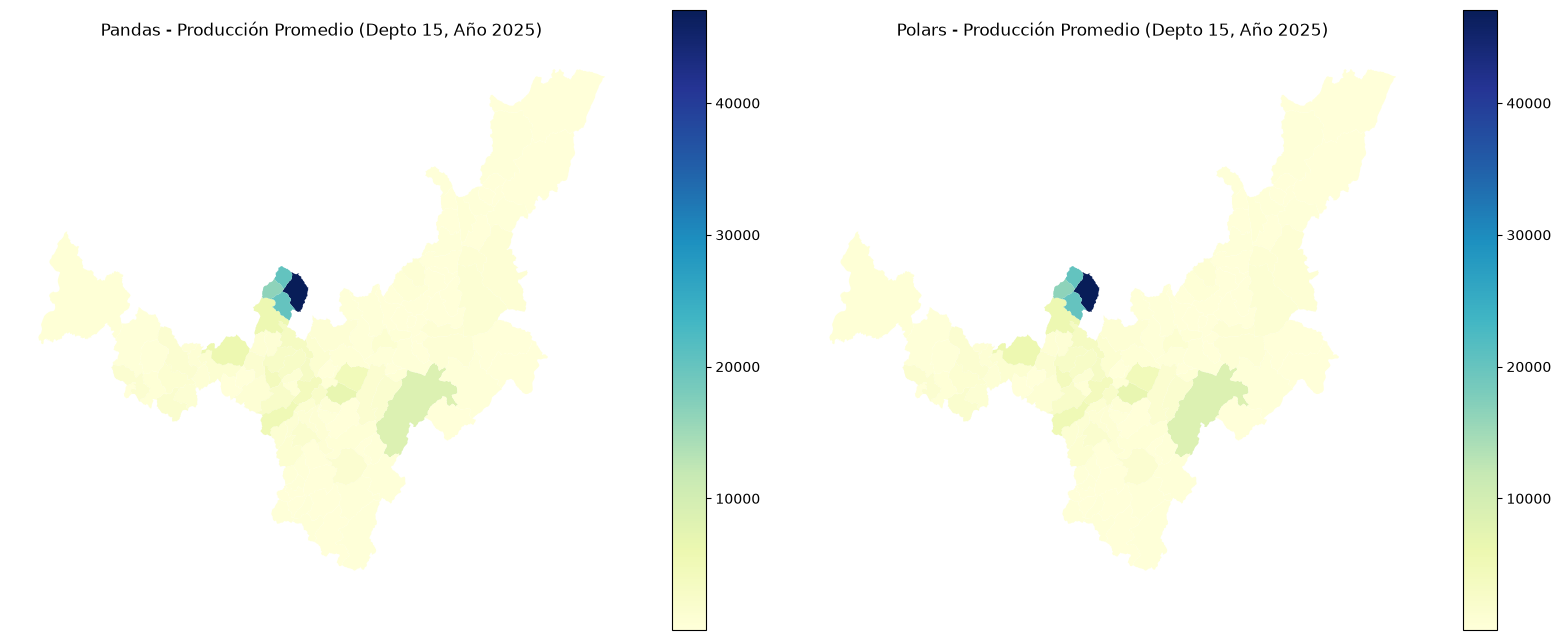

Mapa en: /home/tuptc/big-data-postgraduate/kit/salidas/soluciones/PD05/comparacion_mapas.png


In [6]:
# 5. Llevar resultados tabulares a un mapa

ruta_gpkg = Path(REPO) / "kit/salidas/soluciones/PD04/resultados_espaciales.gpkg"
geometrias = gpd.read_file(ruta_gpkg,layer="municipios",engine="pyogrio")
print(f"Capas cargadas. Registros: {len(geometrias)} | CRS: {geometrias.crs}")

# Seleccionar solo el código municipal y la geometría (asegurando que el código sea de tipo texto con zfill(5))
col_codigo_geo = "codigo_municipio" if "codigo_municipio" in geometrias.columns else "cod_mpio"
geometrias_base = geometrias[[col_codigo_geo, "geometry"]].copy()
geometrias_base[col_codigo_geo] = geometrias_base[col_codigo_geo].astype(str).str.zfill(5)

# Filtro de geometrías del departamento seleccionado
geometrias_depto = geometrias_base[geometrias_base[col_codigo_geo].str.startswith(str(DEPTO_FILTRO).zfill(2))].copy()

# Preparación de Resultados en tablas (Pandas y Polars)

res_pd_pruned = proyeccion_pd[(proyeccion_pd["anio"] == ANIO_FILTRO) & (proyeccion_pd["codigo_departamento"] == DEPTO_FILTRO)].groupby("codigo_municipio", dropna=False).agg({"area_ha": "sum", "produccion_t": "mean"}).reset_index()
res_pl_pruned = proyeccion_pl.filter((pl.col("anio") == ANIO_FILTRO) & (pl.col("codigo_departamento") == DEPTO_FILTRO)).group_by("codigo_municipio").agg([pl.col("area_ha").sum(), pl.col("produccion_t").mean()])

# Convertir el resultado de Polars a Pandas (usando .to_pandas())
df_res_pd = res_pd_pruned.copy()
df_res_pl = res_pl_pruned.to_pandas() if hasattr(res_pl_pruned, "to_pandas") else res_pl_pruned.copy()

# Normalización de columnas de llave de unión
df_res_pd["codigo_municipio"] = df_res_pd["codigo_municipio"].astype(str).str.zfill(5)
df_res_pl["codigo_municipio"] = df_res_pl["codigo_municipio"].astype(str).str.zfill(5)

# Verificación de llave única 
assert df_res_pd["codigo_municipio"].is_unique, "Error: Llaves no únicas en Pandas"
assert df_res_pl["codigo_municipio"].is_unique, "Error: Llaves no únicas en Polars"


# Uniones Espaciales (Merge left one_to_one)

gdf_pd = geometrias_depto.merge(df_res_pd,left_on=col_codigo_geo,right_on="codigo_municipio",how="left",validate="one_to_one")
gdf_pl = geometrias_depto.merge(df_res_pl,left_on=col_codigo_geo,right_on="codigo_municipio",how="left",validate="one_to_one")

# Control Numérico

sin_resultado_pd = gdf_pd["produccion_t"].isna().sum()
sin_geometria_pd = len(df_res_pd[~df_res_pd["codigo_municipio"].isin(geometrias_depto[col_codigo_geo])])

print("Resumen de la union espacial")
print(f"Polígonos en departamento ({DEPTO_FILTRO}): {len(geometrias_depto)}")
print(f"Polígonos sin resultado tabular: {sin_resultado_pd}")
print(f"Resultados tabulares sin polígono: {sin_geometria_pd}")
print(f"Media producción (unión Pandas): {gdf_pd['produccion_t'].mean():.6f}")
print(f"Media producción (unión Polars): {gdf_pl['produccion_t'].mean():.6f}")


# Generación y Guardar de mapas 
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Determinar límites (vmin, vmax)
vmin = min(gdf_pd["produccion_t"].dropna().min(), gdf_pl["produccion_t"].dropna().min())
vmax = max(gdf_pd["produccion_t"].dropna().max(), gdf_pl["produccion_t"].dropna().max())

# Mapa Pandas
gdf_pd.plot(column="produccion_t",ax=axes[0],legend=True,cmap="YlGnBu",missing_kwds={"color": "lightgrey", "label": "Sin Datos"},vmin=vmin,vmax=vmax)
axes[0].set_title(f"Pandas - Producción Promedio (Depto {DEPTO_FILTRO}, Año {ANIO_FILTRO})")
axes[0].axis("off")

# Mapa Polars
gdf_pl.plot(column="produccion_t",ax=axes[1],legend=True,cmap="YlGnBu",missing_kwds={"color": "lightgrey", "label": "Sin Datos"},vmin=vmin,vmax=vmax)
axes[1].set_title(f"Polars - Producción Promedio (Depto {DEPTO_FILTRO}, Año {ANIO_FILTRO})")
axes[1].axis("off")

plt.tight_layout()
ruta_mapa_out = Path(OUT) / "comparacion_mapas.png"
plt.savefig(ruta_mapa_out, dpi=300, bbox_inches="tight")
plt.show()

print(f"Mapa en: {ruta_mapa_out}")

In [7]:
# 6. Reejecución, evidencia y decisión
# Configuración de carpeta aislada para la segunda ejecución
EJECUCION_2 = Path(OUT) / "ejecucion_02"
EJECUCION_2.mkdir(parents=True, exist_ok=True)

vers_pd = pd.__version__
vers_pl = pl.__version__
n_filas_total = len(proyeccion_pd)

registros_mediciones = []


def registrar_medicion(motor,version,operacion,formato,particionamiento,rep,segundos,f_in,f_out,):
  registros_mediciones.append({"motor": motor,"version": version,"operacion": operacion,"formato": formato,
      "particionamiento": particionamiento,"repeticion": rep,"segundos": segundos,"filas_de_entrada": f_in,"filas_de_salida": f_out,})

# Reejecución completa y registro de métricas (Warmup rep = 0 + 5 Repeticiones)

# A. Archivo Único CSV y Parquet (en Pandas)
ruta_csv_u2 = EJECUCION_2 / "datos_unicos.csv"
ruta_pq_u2 = EJECUCION_2 / "datos_unicos.parquet"

for rep in range(0, 6):
  # Escritura CSV
  t0 = time.perf_counter()
  proyeccion_pd.to_csv(ruta_csv_u2, index=False)
  registrar_medicion("pandas",vers_pd,"escritura","csv","ninguno",rep,
      time.perf_counter() - t0,n_filas_total,n_filas_total,)

  # Escritura Parquet
  t0 = time.perf_counter()
  proyeccion_pd.to_parquet(ruta_pq_u2, engine="pyarrow", compression="snappy", index=False)
  registrar_medicion("pandas",vers_pd,"escritura","parquet","ninguno",rep,
      time.perf_counter() - t0,n_filas_total,n_filas_total,)

  # Lectura Parquet Pandas
  t0 = time.perf_counter()
  df_tmp = pd.read_parquet(ruta_pq_u2, engine="pyarrow")
  registrar_medicion("pandas",vers_pd,"lectura","parquet","ninguno",rep,
      time.perf_counter() - t0,n_filas_total,len(df_tmp),)

  # Lectura Parquet Polars (Lazy Scan)
  t0 = time.perf_counter()
  res_l = (pl.scan_parquet(ruta_pq_u2).filter(
          (pl.col("anio") == ANIO_FILTRO) & (pl.col("codigo_departamento") == DEPTO_FILTRO)).collect())
  registrar_medicion("polars",vers_pl,"lectura_lazy","parquet","ninguno",rep,time.perf_counter() - t0,n_filas_total,len(res_l),)

# B. Particionado por Año en EJECUCION_2
dir_por_anio_2 = EJECUCION_2 / "por_anio"
dir_por_anio_2.mkdir(exist_ok=True)

for rep in range(0, 6):
  t0 = time.perf_counter()
  for num, (anio, grupo) in enumerate(proyeccion_pd.groupby("anio", dropna=False)):
    grupo.to_parquet(dir_por_anio_2 / f"parte_{num:04d}.parquet",engine="pyarrow",index=False,)
  seg = time.perf_counter() - t0
  registrar_medicion("pandas",vers_pd,"escritura","parquet","por_anio",rep,seg,n_filas_total,n_filas_total,)

# C. Particionado por Año y Departamento en EJECUCION_2
dir_por_depto_2 = EJECUCION_2 / "por_anio_depto"
dir_por_depto_2.mkdir(exist_ok=True)

for rep in range(0, 6):
  t0 = time.perf_counter()
  for num, ((anio, depto), grupo) in enumerate(proyeccion_pd.groupby(["anio", "codigo_departamento"], dropna=False)):
    grupo.to_parquet(dir_por_depto_2 / f"parte_{num:04d}.parquet",engine="pyarrow",index=False,)
  
  seg = time.perf_counter() - t0
  registrar_medicion("pandas",vers_pd,"escritura","parquet","por_anio_depto",rep,seg,n_filas_total,n_filas_total,)

# Exportación y Resumen de Mediciones
df_mediciones = pd.DataFrame(registros_mediciones)
df_mediciones.to_csv(EJECUCION_2 / "mediciones.csv", index=False)

# Cálculo de la mediana excluyendo la repetición 0 (Warmup)
df_validas = df_mediciones[df_mediciones["repeticion"] > 0]
df_resumen_medianas = (df_validas.groupby(["motor", "operacion", "formato", "particionamiento"])
    .agg(mediana_segundos=("segundos", "median"),min_segundos=("segundos", "min"),max_segundos=("segundos", "max"),
        filas_salida=("filas_de_salida", "first"),)
    .reset_index())

print(" Resumen de medianas (excluyendo warmup rep=0) ")
display(df_resumen_medianas)

# Inventario de la Segunda Ejecución y Controles de Auditoría
archivos_e2 = [f for f in EJECUCION_2.rglob("*") if f.is_file()]
bytes_totales_e2 = sum(f.stat().st_size for f in archivos_e2)

print("\nResumen de ejecución 2")
print(f"Ruta de reejecución aislada: {EJECUCION_2}")
print(f"Archivos totales generados: {len(archivos_e2)}")
print(f"Espacio total ocupado: {bytes_totales_e2 / (1024**2):.2f} MB")
print(f"¿Hay coincidencia de filas con el origen?: {n_filas_total == len(df_tmp)}")

 Resumen de medianas (excluyendo warmup rep=0) 


,motor,operacion,formato,particionamiento,mediana_segundos,min_segundos,max_segundos,filas_salida
0,pandas,escritura,csv,ninguno,0.212094,0.208703,0.214910,166732
1,pandas,escritura,parquet,ninguno,0.043430,0.043131,0.044619,166732
2,pandas,escritura,parquet,por_anio,0.065439,0.064943,0.065830,166732
3,pandas,escritura,parquet,por_anio_depto,0.286465,0.281462,0.319203,166732
4,pandas,lectura,parquet,ninguno,0.011662,0.011565,0.014267,166732
5,polars,lectura_lazy,parquet,ninguno,0.004217,0.003810,0.004329,2709



Resumen de ejecución 2
Ruta de reejecución aislada: /home/tuptc/big-data-postgraduate/kit/salidas/soluciones/PD05/ejecucion_02
Archivos totales generados: 234
Espacio total ocupado: 13.01 MB
¿Hay coincidencia de filas con el origen?: True


### Diagnóstico

#### Respuestas a las Preguntas de Evaluación
1. **¿Qué parte mejora con Parquet?**  
   Mejora la eficiencia en I/O (lectura/escritura en disco) y el tamaño de almacenamiento gracias a la compresión columnar (Snappy), donde se reduce el espacio consumido frente a CSV y permite el filtrado rápido de columnas sin cargar todo el dataset en memoria.

2. **¿Cuándo ayuda la selección de particiones y qué diseño genera archivos demasiado pequeños?**  
   * Ayuda cuando uando se realizan consultas o filtros frecuentes por una columna en particular, se evita el escaneo completo de los datos y particionar por columnas de alta cardinalidad (con demasiados valores únicos) genera miles de archivos pequeños de pocos kilobytes, empeorando el rendimiento.

3. **¿Qué cambia entre tiempo en memoria y tiempo desde disco?**  
   El tiempo en disco incluye la latencia de lectura física y descompresión, mientras que el tiempo en memoria mide las operaciones vectorizadas directas del procesador sobre el DataFrame cargado. En volúmenes medianos como este (92k filas), la diferencia de ejecución en RAM es mínima, pero el tiempo de carga desde disco favorece ampliamente a Parquet.

4. **¿Qué elegirías para este conjunto y por qué?**  
   Para este volumen de datos (alrededor de 92,000 registros), la opción más eficiente es utilizar **Parquet no particionado o particionado por una variable de baja cardinalidad**

#### Recomendación Final
Para el volumen de información (92,738 registros), se recomienda **almacenar el dataset en formato Parquet consolidado (un solo archivo o particionado únicamente a nivel departamental)**. Un particionamiento más granular (por municipio) resulta contraproducente por la generación excesiva de archivos pequeños (*overhead* de metadatos). 
Por otro lado, aunque **Polars** es más veloz en lectura analítica por su motor y evaluación diferida (`lazy execution`), **Pandas** es suficientemente funcional para esta escala, por lo que la elección del formato de almacenamiento importa más a la hora de evaluar rendimiento.

In [8]:
#Depurado